# KITScenes — HD maps

Every scene of the train, val and overlap splits ships its Lanelet2 HD map in the frame of its poses. `kitscenes.map`
gives two views of it:

- **`SceneMap`**: the map as typed numpy elements (lanes with boundaries, centerline, speed limit and neighbours;
  lines such as curbs and markings; stop lines, signs, lights) with region queries, lane matching and routing;
- **`MLConverter`**: map labels for learning, from `lanelet2.ml_converter`: compound polylines (dividers, road
  borders, centerlines, crosswalks, ...) and traffic elements around a pose, in the vehicle frame.

**Needs:** `kitscenes[map,viz]` installed as in the README (the `[map]` extra installs the KITScenes lanelet2 build
with the ML converter on Linux x86_64, Python 3.9–3.13) and a scene of a split with maps.
The example scene and how to download it alone: notebook 01.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np

import kitscenes

%matplotlib inline
plt.rcParams["figure.dpi"] = 72  # small figures

DATASET_ROOT = os.environ.get("KITSCENES_ROOT", "/data/kitscenes")  # or an absolute path
SCENE_ID = "c34c778f-ad8c-0aa9-7e1a-c86a73f887c7"  # the example scene (notebook 01); any scene UUID on disk works

from kitscenes.map import Circle, MLConverter, Region, has_ml_converter, project_to_camera
from kitscenes.visualization import MapLayer, plot_top_down, render_frame

print("ML converter:", has_ml_converter())

# lanelet2 notes on the routing graphs of the maps (SceneMap.routing_problems lists them): not shown here
import logging
import warnings

from kitscenes.map import MapProblemWarning

warnings.filterwarnings("ignore", category=MapProblemWarning)
logging.getLogger("kitscenes.map.scene_map").addFilter(lambda record: "routing graph" not in record.getMessage())

ML converter: True


In [2]:
ds = kitscenes.open(DATASET_ROOT)  # every split under the root
scene = ds[SCENE_ID]
frame = scene[min(50, len(scene) - 1)]
print(scene.info)

SceneInfo(scene_id='c34c778f-ad8c-0aa9-7e1a-c86a73f887c7', split='val', city='Frankfurt', lidar='velodyne', num_frames=220, recording_week='2025-W34', time_of_day='afternoon', light='day', sun_below_horizon=False, dark=False, recording_order=779, drive=11, order_in_drive=258, rig='velodyne_2025', sd_snapshot='Frankfurt_2025-W34.osm.pbf', duration_s=21.9, distance_m=174.0, mean_speed_mps=8.0, max_speed_mps=10.0, road_motorway_share=0.0, road_arterial_share=1.0, road_local_share=0.0, road_service_share=0.0, road_unmatched_share=0.0, road_dominant='arterial', speed_limit_kph_median=50.0, weather='partly_cloudy', road_surface='dry', weather_confidence='high')


## 1. Querying the map

`scene.map` loads the map on first use (a second or so). Queries take a region: a `Region` (a rectangle around the
vehicle, placed at a pose with `.around(pose)`), a `Circle`, or nothing for the whole map. Results are in the map frame
(the frame of `frame.pose`); `query(...).in_ego(pose)` moves everything into the vehicle frame.

In [3]:
smap = scene.map
region = Region(ahead=60, behind=20, left=25, right=25)
box = region.around(frame.pose)
lanes = smap.lanes(box)
print(f"{len(lanes)} lanes in the box:", {k: sum(l.kind.value == k for l in lanes) for k in {l.kind.value for l in lanes}})
print(lanes[0])
print("line types:", sorted({f"{l.type}/{l.subtype}".rstrip("/") for l in smap.lines(box)})[:12], "...")

115 lanes in the box: {'emergency_lane': 2, 'road': 87, 'bicycle_lane': 19, 'crosswalk': 7}
Lane(id=23567, kind='crosswalk', left=21925, right=22909, left_points=<float64 (6, 3)>, right_points=<float64 (4, 3)>, centerline=<float64 (7, 3)>, speed_limit_mps=None, vehicle=False, one_way=False, successors=(), predecessors=(), left_neighbor=None, right_neighbor=None, regulatory_ids=())
line types: ['arrow/left', 'arrow/right', 'arrow/straight', 'arrow/straight_right', 'bike_marking/dashed', 'bike_marking/solid', 'curbstone/high', 'curbstone/low', 'line_thick/dashed', 'line_thin/dashed', 'line_thin/solid', 'pedestrian_marking'] ...


MapPatch(lanes=[115 Lane], lines=[346 MapLine], stop_lines=[8 StopLine], traffic_signs=[49 TrafficSign], traffic_lights=[21 TrafficLight], frame='ego')


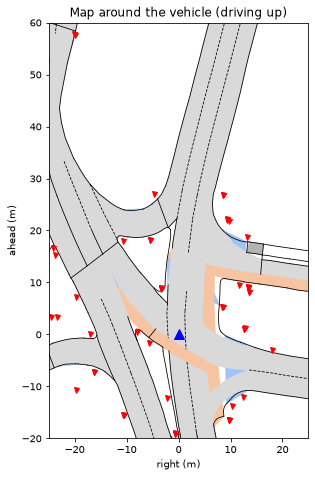

In [4]:
patch = smap.query(box).in_ego(frame.pose)
print(patch)
colours = {"road": "0.85", "bicycle_lane": "#f6c4a0", "crosswalk": "#9ec5f8", "bus_lane": "#f8e19e"}

fig, ax = plt.subplots(figsize=(6, 7.5))
for lane in patch.lanes:
    outline = np.vstack([lane.left_points[:, :2], lane.right_points[::-1, :2]])
    ax.fill(-outline[:, 1], outline[:, 0], color=colours.get(lane.kind.value, "0.7"), zorder=1)
for line in patch.lines:
    if line.type in ("curbstone", "road_border", "line_thin", "line_thick", "stop_line"):
        ax.plot(-line.points[:, 1], line.points[:, 0], "k-" if line.subtype != "dashed" else "k--", linewidth=0.8)
for sign in patch.traffic_signs:
    ax.plot(-sign.points[:, 1].mean(), sign.points[:, 0].mean(), "rv", markersize=5)
ax.plot(0, 0, "b^", markersize=10)
ax.set(xlim=(-25, 25), ylim=(-20, 60), aspect="equal", title="Map around the vehicle (driving up)",
       xlabel="right (m)", ylabel="ahead (m)")
plt.show()

## 2. Where am I, and where can I go?

`smap.match(pose)` gives the lanes the vehicle may be driving on (heading-aware); lanes know their successors and
neighbours, and `smap.route(from_lane, to_lane)` finds the shortest route through the routing graph (lanelet2's
`smap.routing_graph` and `smap.lanelet_map` are there when you need more).

In [5]:
match = smap.match(frame.pose)
print(match)
if match:
    here = smap.lane(match[0].lane_id)
    print(f"lane {here.id}: {here.kind.value}, speed limit "
          f"{here.speed_limit_kph if here.speed_limit_kph else float('nan'):.0f} km/h, successors {here.successors}")
    end = smap.match(scene[len(scene) - 1].pose)
    if end:
        route = smap.route(here.id, end[0].lane_id)
        print("route to the lane of the last frame:", route)

[LaneMatch(lane_id=24541, reversed=False, distance=0.0, heading_error=0.04028981892496519)]
lane 24541: road, speed limit 50 km/h, successors (24482,)
route to the lane of the last frame: [24541, 24482, 23809, 23814, 23816, 24426, 25700, 24556, 25220, 24958, 23716, 23693, 23692, 24695, 24011, 24762, 24274]


Crosswalks are lanes of kind `crosswalk`; `smap.drivable_lanes()` are the lanes a vehicle may use. Map points go into a
camera through the pose with `project_to_camera`:

9 crosswalks within 80 m


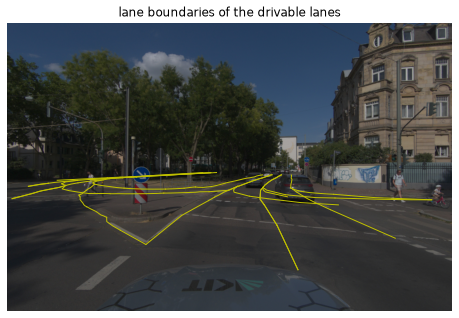

In [6]:
crosswalks = smap.lanes(Circle.around(frame.pose, 80), kinds=["crosswalk"])
print(f"{len(crosswalks)} crosswalks within 80 m")
cam = scene.rig.cameras["camera_ring_front"]
image = frame.image("camera_ring_front", reduce=4)
plt.figure(figsize=(8, 5.2))
plt.imshow(image)
for lane in smap.drivable_lanes(box):
    for points in (lane.left_points, lane.right_points):
        uv, depth, visible = project_to_camera(points, frame.pose, cam.scaled(1 / 4))
        if visible.all():
            plt.plot(uv[:, 0], uv[:, 1], "y-", linewidth=1)
plt.xlim(0, image.shape[1]); plt.ylim(image.shape[0], 0); plt.axis("off")
plt.title("lane boundaries of the drivable lanes")
plt.show()

## 3. Map labels for learning

`MLConverter.for_scene(scene, grouping=..., region=...)` labels the region around a pose: `labels.lines` and
`labels.traffic_elements` are dicts by type, each a list of (N, 3) arrays in the base frame at that pose (every type
of the label set is a key, an empty list where there is none). `grouping` picks the label set (`"default"`,
`"road_border_merged"`, `"maptr"`, `"m3tr"`). `labels.line_ids` are the map elements behind each line,
`labels.te_to_centerline` links traffic elements to the lane they apply to.

In [7]:
conv = MLConverter.for_scene(scene, grouping="m3tr", region=Region(ahead=40, behind=20, left=20, right=20))
labels = conv(frame.pose)
print(labels)
for name, lines in labels.lines.items():
    print(f"{name:20s} {len(lines):3d} lines")
print("stop lines:", len(labels.traffic_elements["StopLine"]), "| map_change scene:", labels.map_changed)

MapLabels(lines={'RoadBorder': [14 ndarray], 'Dashed': [21 ndarray], 'Solid': [14 ndarray], 'Virtual': [24 ndarray], 'Centerline': [11 ndarray], 'BikeCenterline': [4 ndarray], 'Unknown': [], 'DrivableArea': [9 ndarray], 'PedestrianCrossing': [4 ndarray]}, line_ids={'RoadBorder': [14 tuple], 'Dashed': [21 tuple], 'Solid': [14 tuple], 'Virtual': [24 tuple], 'Centerline': [11 tuple], 'BikeCenterline': [4 tuple], 'Unknown': [], 'DrivableArea': [9 tuple], 'PedestrianCrossing': [4 tuple]}, traffic_elements={36 items}, traffic_element_ids={36 items}, te_to_centerline=[13 tuple], te_to_te=[7 tuple], pose=EgoPose(t_ns=5051987968, xyz=[ -521.3529, -1015.1191,   146.8557], quat=[ 0.002 , -0.0015,  0.3782,  0.9257]), region=Region(ahead=40, behind=20, left=20, right=20), dims=3, map_changed=False, line_pieces={'RoadBorder': [14 int], 'Dashed': [21 int], 'Solid': [14 int], 'Virtual': [24 int], 'Centerline': [11 int], 'BikeCenterline': [0, 0, 0, 0], 'Unknown': [], 'DrivableArea': [9 int], 'Pedestria

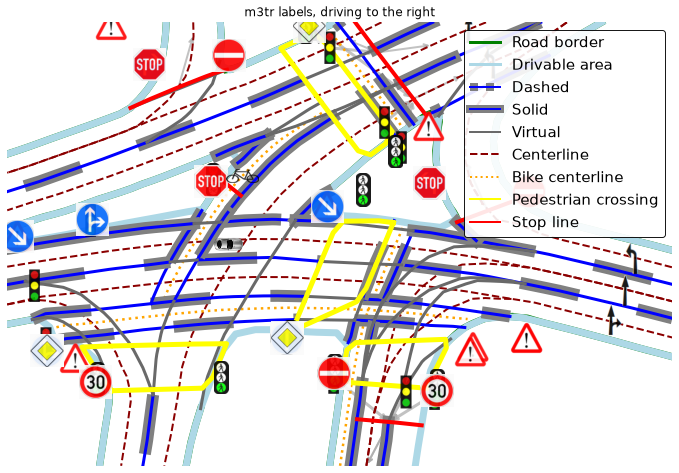

In [8]:
fig, ax = plt.subplots(figsize=(16, 8))
plot_top_down(labels, ax, orientation="horizontal")
ax.set_title("m3tr labels, driving to the right")
plt.show()

Points per line: 20 per line by default; `sampling=Spacing(1.0)` gives a point per metre, `Adaptive(0.05, 5.0)` keeps
the map's vertices where a line bends, `None` keeps them all. `dims=2` is the converter's 2D mode. In the cameras, the
labels are drawn by `render_frame` with a `MapLayer` (styled by type, signs as icons):

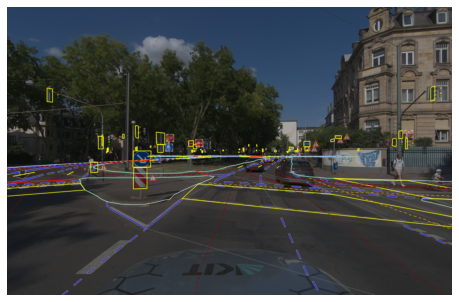

In [9]:
images = render_frame(frame, map_layer=MapLayer(scene, grouping="m3tr"), cameras=["camera_ring_front"], reduce=4)
plt.figure(figsize=(8, 5.2))
plt.imshow(images["camera_ring_front"])
plt.axis("off")
plt.show()

### Vector-map labels: the MapTR preset

`kitscenes.MapLabelSpec.maptr()` gives the classes of MapTR and its successors in the 60 x 30 m box around the vehicle:
`divider` (lane markings), `ped_crossing` (closed crosswalk outlines clipped by the box, one per crossing), `boundary`
(the drivable-space border) and, with `centerline=True`, `centerline`, 20 points each, in the base frame. Lines more
than 4 m above or below the road (a bridge across the box) are cut away. Every element has a key
`(class, map element ids, piece)`; with `chaining="scene"` it stays the same over the scene.
The same spec goes into `SampleSpec(frame="road", map_labels=...)` (notebook 05): the preset is for the road frame
of the map benchmark (`frame="road"`), where the labels are lifted onto the road; `spec.labels(frame)` does the same.

{'divider': 28, 'ped_crossing': 5, 'boundary': 7, 'centerline': 11}
keys of the dividers: [('divider', (19448, 19782, 19064, 23405, 20496, 23228, 23384, 22589, 23269, 23261), 0), ('divider', (23267, 22586, 23388, 23230, 21071, 21893, 19040), 0), ('divider', (23272, 22596, 23386, 21768, 23093, 23275, 20197), 0)]


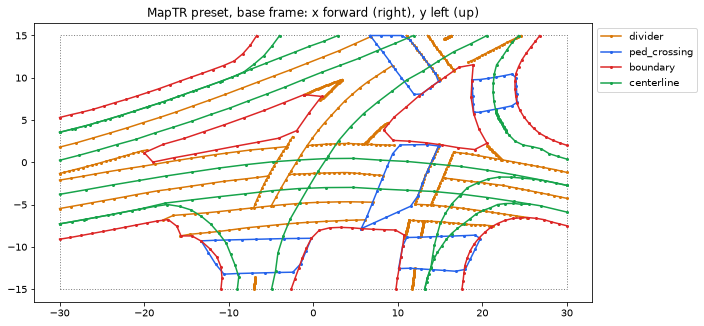

In [10]:
spec = kitscenes.MapLabelSpec.maptr(centerline=True)
maptr = spec.converter(scene)(frame.pose)
print({name: len(lines) for name, lines in maptr.lines.items()})
print("keys of the dividers:", maptr.line_keys("divider")[:3])

colours = {"divider": "#d97706", "ped_crossing": "#2563eb", "boundary": "#dc2626", "centerline": "#16a34a"}
fig, ax = plt.subplots(figsize=(10, 5.5))
for name, lines in maptr.lines.items():
    for k, line in enumerate(lines):
        ax.plot(line[:, 0], line[:, 1], ".-", color=colours[name], markersize=4, label=None if k else name)
ax.add_patch(plt.Rectangle((-30, -15), 60, 30, fill=False, linestyle=":", color="0.5"))
ax.set_aspect("equal")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title("MapTR preset, base frame: x forward (right), y left (up)")
plt.show()

## 4. The future drive on the map

`frame.future(horizon_s)` is the ego trajectory after the frame in the same base frame as the labels, so both go onto
one plot (`valid` marks the slots the recorded poses cover):

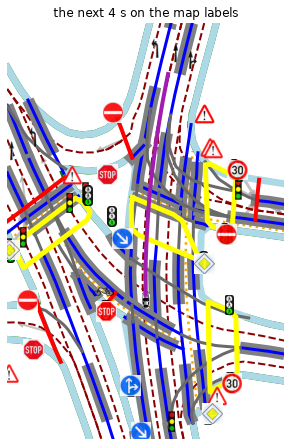

In [11]:
future = frame.future(4.0)
path = future.xyz_ego[future.valid]
fig, ax = plt.subplots(figsize=(5, 7.5))
plot_top_down(labels, ax, show_legend=False)
ax.plot(-path[:, 1], path[:, 0], color="#a21caf", linewidth=4, zorder=20)  # vertical: x up, y to the left
ax.set_title("the next 4 s on the map labels")
plt.show()

## 5. City maps

The dataset root also has the HD maps of the three cities (`lanelet2_hd_maps/<City>.osm`, with the test regions cut
out); `ds.city_maps()` lists them. The poses of every scene of a city are in one frame, the city's map frame
(`kitscenes.map.origin.CITY_ORIGINS`). So `SceneMap(path, CITY_ORIGINS[city])` loads a city map in the frame of all its
scenes, e.g. to label beyond a scene's own map. `scene.load_map(path)` gives the same for a scene with a map.
Notebook 08 draws the splits and the night drives on the city maps; notebook 07 is about the OpenStreetMap SD maps.

In [12]:
from kitscenes.map import SceneMap
from kitscenes.map.origin import CITY_ORIGINS

city_maps = ds.city_maps()
print(city_maps or "no city maps under this root")
cities = {city: SceneMap(path, CITY_ORIGINS[city]) for city, path in city_maps.items()}  # each read on first use
here = cities[scene.info.city]
print(len(here.lanes(Circle.around(frame.pose, 200))), "lanes within 200 m of the frame in", here)

{'Frankfurt': PosixPath('/data/kitscenes/lanelet2_hd_maps/Frankfurt.osm'), 'Karlsruhe': PosixPath('/data/kitscenes/lanelet2_hd_maps/Karlsruhe.osm'), 'Sindelfingen': PosixPath('/data/kitscenes/lanelet2_hd_maps/Sindelfingen.osm')}


596 lanes within 200 m of the frame in SceneMap('/data/kitscenes/lanelet2_hd_maps/Frankfurt.osm', origin=(50.11042, 8.68214), 22636 lanes)
